# 4.2. Notebook 02  Préparation des données
## Préparation
## 1.Nettoyage
## 2.Encodage
## 3.Normalisation
## 4.Détection d’outliers
## 5.Split train/test (supervisé)
## 6.Toutes les fonctions dans utils/preprocessing.py

# 0. Installeation des bibliothèques

In [37]:
import sys
import os

# Ajouter le dossier racine du projet (project) au PYTHONPATH
project_root = os.path.abspath("..")
sys.path.append(project_root)

print("Project root:", project_root)


Project root: C:\Users\DELL\Music\project


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from utils.preprocessing import (
    clean_df,
    encode_labels,
    remove_outliers,
    normalize_df
)

import warnings
warnings.filterwarnings('ignore')


In [39]:
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12


In [40]:

from sklearn.preprocessing import StandardScaler, LabelEncoder
from utils.preprocessing import load_df, clean_df, normalize_df
from utils.preprocessing import encode_labels, normalize_features
from utils.preprocessing import *

In [41]:
df = pd.read_csv(r"C:\Users\DELL\Music/project/ data/Cance_Pediction_Dataset.csv")

In [42]:
data_path = r'C:\Users\DELL\Music/project/ data/Cance_Pediction_Dataset.csv'

In [43]:
import utils
print("utils chargé avec succès")


utils chargé avec succès


In [44]:
import sys
import importlib

# Supprimez le module utils du cache
if 'utils' in sys.modules:
    del sys.modules['utils']
if 'utils.models' in sys.modules:
    del sys.modules['utils.models']

# Rechargez le module
import utils
importlib.reload(utils)

print(" Module utils rechargé")

 Module utils rechargé


In [45]:

def extract_dataframe(data):
    """
    Extrait un DataFrame d'un objet, même si c'est un tuple
    """
    if isinstance(data, pd.DataFrame):
        return data
    elif isinstance(data, tuple):
        # Chercher un DataFrame dans le tuple
        for item in data:
            if isinstance(item, pd.DataFrame):
                return item
        # Si aucun DataFrame, retourner le premier élément
        return data[0] if len(data) > 0 else pd.DataFrame()
    else:
        # Si ce n'est ni DataFrame ni tuple, essayer de convertir
        try:
            return pd.DataFrame(data)
        except:
            return pd.DataFrame()

In [46]:
from utils.preprocessing import (
    load_df,
    clean_df,
    handle_missing_values,
    encode_labels,
    normalize_df,
    normalize_features,
    remove_outliers,
    split_data,
    normalize_train_test,
    preprocess_pipeline,
    get_data_summary,
    handle_missing_values,
    save_processed_data
)

In [47]:
# Chargement avec notre fonction

df = load_df(data_path)
print(f" Fichier chargé: {data_path}")
print(f" Dimensions: {df.shape[0]} lignes × {df.shape[1]} colonnes")

# Vérifier le type de df
print(f"\n🔧 Type de df: {type(df)}")
print(f"   Est-ce un DataFrame? {isinstance(df, pd.DataFrame)}")


 Fichier chargé: C:\Users\DELL\Music/project/ data/Cance_Pediction_Dataset.csv
 Dimensions: 1000 lignes × 9 colonnes

🔧 Type de df: <class 'pandas.core.frame.DataFrame'>
   Est-ce un DataFrame? True


In [48]:
from utils.preprocessing import remove_outliers


In [49]:
from utils.preprocessing import load_df, clean_df, remove_outliers, normalize_df, encode_labels, split_data


# 1.NETTOYAGE DES DONNÉES (CLEANING)

In [50]:
df_clean = clean_df(df)

In [51]:
print(f"   Dimensions avant: {df.shape}")

   Dimensions avant: (1000, 9)


In [52]:
print(f"   Dimensions après: {df_clean.shape}")

   Dimensions après: (1000, 9)


In [53]:

# Vérification des valeurs manquantes après nettoyage
missing_after = df_clean.isnull().sum().sum()
print(f"   Valeurs manquantes après nettoyage: {missing_after}")

   Valeurs manquantes après nettoyage: 0


In [54]:
# Vérification des doublons
duplicates = df_clean.duplicated().sum()
print(f"   Lignes dupliquées: {duplicates}")

   Lignes dupliquées: 0


In [55]:
df_encoded = df.copy()  #  pipeline propre + encoder

In [56]:
print("\n" + "=" * 70)
print(" NETTOYAGE INITIAL")
print("=" * 70)

print("\n🔧 Application de clean_df()...")
# S'assurer que df est un DataFrame, pas un tuple
if isinstance(df, tuple):
    print(f"⚠️  Attention: df est un tuple, extraction du DataFrame...")
    df = df[0] if isinstance(df[0], pd.DataFrame) else df

df_clean = clean_df(df)
print(f"✅ Nettoyage terminé")
print(f"   Avant: {df.shape}")
print(f"   Après: {df_clean.shape}")

# S'assurer que df_clean est un DataFrame
print(f"   Type de df_clean: {type(df_clean)}")




 NETTOYAGE INITIAL

🔧 Application de clean_df()...
✅ Nettoyage terminé
   Avant: (1000, 9)
   Après: (1000, 9)
   Type de df_clean: <class 'pandas.core.frame.DataFrame'>


In [57]:
# GESTION DES VALEURS MANQUANTES
# Analyse des valeurs manquantes avant traitement
print("\n Analyse des valeurs manquantes:")
missing_before = df_clean.isnull().sum()
missing_cols = missing_before[missing_before > 0]

if len(missing_cols) > 0:
    print(f"   Colonnes avec valeurs manquantes: {len(missing_cols)}")
    for col, count in missing_cols.items():
        percentage = (count / len(df_clean)) * 100
        print(f"   • {col}: {count} valeurs ({percentage:.2f}%)")
else:
    print("   ✅ Aucune valeur manquante détectée")


 Analyse des valeurs manquantes:
   ✅ Aucune valeur manquante détectée


In [58]:
# Appliquer handle_missing_values avec stratégie 'median' pour les numériques, 'mode' pour les catégorielles
print("\n🔧 Application de handle_missing_values...")
df_no_missing = handle_missing_values(df_clean, strategy='median')
print(f"✅ Valeurs manquantes traitées")
print(f"   Valeurs manquantes restantes: {df_no_missing.isnull().sum().sum()}")


🔧 Application de handle_missing_values...
✅ Valeurs manquantes traitées
   Valeurs manquantes restantes: 0


In [59]:
#Suppression des valeurs nulles
df.dropna()

,PatientID,first_name,last_name,BirthDate,gender,Obesity,Smoking,Genetic Risk,Cancer Prediction Level
1,2.0,Heinrik,Baelde,9/25/1992,Male,Obésité de classe II,No,Yes,Medium
3,4.0,Ninette,Checchetelli,3/21/2007,Homme,Obésité de classe I,Yes,No,Low
4,5.0,Neala,Dible,7/10/2006,Femme,Obesité exteme,No,Maybe,Medium
5,6.0,Prudy,Amer,9/2/2018,F,Obésité de classe III,No,Yes,Low
7,8.0,Cassandre,Matveiko,11/18/1997,H,Poids normal Surpoids,No,Maybe,Low
...,...,...,...,...,...,...,...,...,...
995,996.0,Luke,Mongeot,9/7/1937,H,Obésité de classe III,No,Yes,Medium
996,997.0,Fran,Stoggell,8/5/1943,Femme,Sous-poids,No,No,High
997,998.0,Jase,Paaso,6/8/1963,H,Poids normal Surpoids,Yes,Yes,High
998,999.0,Charlot,Woolis,9/13/1940,Femme,Obésité de classe I,Yes,Maybe,High


In [60]:
#Supprimer les valeurs dupliquées
df.drop_duplicates()

,PatientID,first_name,last_name,BirthDate,gender,Obesity,Smoking,Genetic Risk,Cancer Prediction Level
0,1.0,Marlee,Merrgen,7/29/2011,Homme,Obésité de classe II,Yes,NaN,Medium
1,2.0,Heinrik,Baelde,9/25/1992,Male,Obésité de classe II,No,Yes,Medium
2,3.0,NaN,Duffyn,5/10/1950,Homme,Poids normal Surpoids,Yes,Maybe,Low
3,4.0,Ninette,Checchetelli,3/21/2007,Homme,Obésité de classe I,Yes,No,Low
4,5.0,Neala,Dible,7/10/2006,Femme,Obesité exteme,No,Maybe,Medium
...,...,...,...,...,...,...,...,...,...
995,996.0,Luke,Mongeot,9/7/1937,H,Obésité de classe III,No,Yes,Medium
996,997.0,Fran,Stoggell,8/5/1943,Femme,Sous-poids,No,No,High
997,998.0,Jase,Paaso,6/8/1963,H,Poids normal Surpoids,Yes,Yes,High
998,999.0,Charlot,Woolis,9/13/1940,Femme,Obésité de classe I,Yes,Maybe,High


In [61]:
# Modifier la colonne 'Smoking'
df['Smoking'] = df['Smoking'].replace({'Yes': 1, 'No': 0})
print(df['Smoking'])


0      1
1      0
2      1
3      1
4      0
      ..
995    0
996    0
997    1
998    1
999    1
Name: Smoking, Length: 1000, dtype: int64


In [62]:
#Pour fusionne les noms et les prénoms des patients
df['Full_Name'] = df['first_name'] + ' ' + df['last_name']
df.head(5)

,PatientID,first_name,last_name,BirthDate,gender,Obesity,Smoking,Genetic Risk,Cancer Prediction Level,Full_Name
0,1.0,Marlee,Merrgen,7/29/2011,Homme,Obésité de classe II,1,NaN,Medium,Marlee Merrgen
1,2.0,Heinrik,Baelde,9/25/1992,Male,Obésité de classe II,0,Yes,Medium,Heinrik Baelde
2,3.0,NaN,Duffyn,5/10/1950,Homme,Poids normal Surpoids,1,Maybe,Low,NaN
3,4.0,Ninette,Checchetelli,3/21/2007,Homme,Obésité de classe I,1,No,Low,Ninette Checchetelli
4,5.0,Neala,Dible,7/10/2006,Femme,Obesité exteme,0,Maybe,Medium,Neala Dible


In [63]:
#Suppression des colonnes non pertinentes
df = df.drop(columns=['PatientID', 'Full_Name', 'last_name', 'first_name'])

In [64]:
df.columns

Index(['BirthDate', 'gender', 'Obesity', 'Smoking', 'Genetic Risk',
       'Cancer Prediction Level'],
      dtype='object')

# 2. ENCODAGE DES VARIABLES CATÉGORIELLES

In [65]:
# Identification des colonnes catégorielles
categorical_cols = df_no_missing.select_dtypes(include=['object']).columns
print(f"\n🎯 Colonnes catégorielles identifiées: {len(categorical_cols)}")
if len(categorical_cols) > 0:
    for col in categorical_cols:
        unique_vals = df_no_missing[col].nunique()
        print(f"   • {col}: {unique_vals} valeurs uniques")


🎯 Colonnes catégorielles identifiées: 8
   • first_name: 904 valeurs uniques
   • last_name: 985 valeurs uniques
   • BirthDate: 976 valeurs uniques
   • gender: 6 valeurs uniques
   • Obesity: 6 valeurs uniques
   • Smoking: 2 valeurs uniques
   • Genetic Risk: 3 valeurs uniques
   • Cancer Prediction Level: 3 valeurs uniques


In [66]:
# Encodage avec encode_labels
print("\n🔧 Encodage des variables catégorielles...")
if len(categorical_cols) > 0:
    df_encoded, label_encoders = encode_labels(df_no_missing, categorical_cols)
    print(f"✅ Encodage terminé")
    print(f"   Encodeurs créés: {len(label_encoders)}")
      # Afficher le mapping pour chaque encodeur
    for col, encoder in label_encoders.items():
        print(f"\n   Mapping pour '{col}':")
        for label, code in zip(encoder.classes_, range(len(encoder.classes_))):
            print(f"     {label} → {code}")
else:
    df_encoded = df_no_missing.copy()
    label_encoders = {}
    print("   ℹ️  Aucune colonne catégorielle à encoder")

print(f"\n📊 Types de données après encodage:")
print(df_encoded.dtypes.value_counts())


🔧 Encodage des variables catégorielles...
✅ Encodage terminé
   Encodeurs créés: 8

   Mapping pour 'first_name':
     Abbe → 0
     Adamo → 1
     Addy → 2
     Adelbert → 3
     Adlai → 4
     Adriaens → 5
     Ailee → 6
     Ailey → 7
     Aimee → 8
     Alberta → 9
     Alden → 10
     Aldon → 11
     Alec → 12
     Alexandrina → 13
     Alfons → 14
     Alfonse → 15
     Alick → 16
     Alikee → 17
     Alisa → 18
     Alleen → 19
     Alvira → 20
     Alysia → 21
     Amabel → 22
     Amalea → 23
     Amalee → 24
     Amandie → 25
     Amber → 26
     Ambros → 27
     Amerigo → 28
     Anastassia → 29
     Andrew → 30
     Andris → 31
     Anestassia → 32
     Angelina → 33
     Annaliese → 34
     Annamarie → 35
     Anne-marie → 36
     Annette → 37
     Annice → 38
     Annora → 39
     Antoine → 40
     Antonia → 41
     Anya → 42
     Appolonia → 43
     Ara → 44
     Arabel → 45
     Arabela → 46
     Arch → 47
     Ardene → 48
     Ardine → 49
     Ardisj → 50
     Ardyth

# 3.Normalisation


In [67]:
# Identification de la colonne cible
df_no_outliers = df.copy()
target_col = 'Cancer Prediction Level'
if target_col in df_no_outliers.columns:
    print(f"\n🎯 Colonne cible identifiée: '{target_col}'")
    exclude_cols = [target_col]
else:
    print(f"\n⚠️  Colonne cible '{target_col}' non trouvée")
    print("   Vérifiez les colonnes disponibles:")
    print(f"   {list(df_no_outliers.columns)}")
    exclude_cols = []

# Normalisation avec normalize_df
print("\n🔧 Normalisation des données...")
if len(exclude_cols) > 0:
    df_normalized, scaler = normalize_df(df_no_outliers, exclude_cols=exclude_cols)
else:
    df_normalized, scaler = normalize_df(df_no_outliers)

print(f"✅ Normalisation terminée")
print(f"   Scaler utilisé: {type(scaler).__name__ if scaler else 'Aucun'}")

# Vérification de la normalisation
if scaler:
    print("\n📊 Vérification de la normalisation:")
    numeric_cols = df_normalized.select_dtypes(include=[np.number]).columns
    if len(numeric_cols) > 0:
        # Exclure la cible si elle est numérique
        if target_col in numeric_cols:
            numeric_cols = numeric_cols.drop(target_col)
        
        if len(numeric_cols) > 0:
            sample_cols = numeric_cols[:3]  # Vérifier 3 colonnes
            for col in sample_cols:
                mean_val = df_normalized[col].mean()
                std_val = df_normalized[col].std()
                print(f"   • {col}: mean={mean_val:.6f}, std={std_val:.6f} "
                      f"(idéal: mean≈0, std≈1)")


🎯 Colonne cible identifiée: 'Cancer Prediction Level'

🔧 Normalisation des données...
✅ Normalisation terminée
   Scaler utilisé: StandardScaler

📊 Vérification de la normalisation:
   • Smoking: mean=-0.000000, std=1.000500 (idéal: mean≈0, std≈1)


## 4. DÉTECTION ET TRAITEMENT DES OUTLIERS


🔍 Détection visuelle des outliers...
   • PatientID: 0 outliers détectés (0.00%)
   • first_name: 0 outliers détectés (0.00%)
   • last_name: 0 outliers détectés (0.00%)
   • BirthDate: 0 outliers détectés (0.00%)


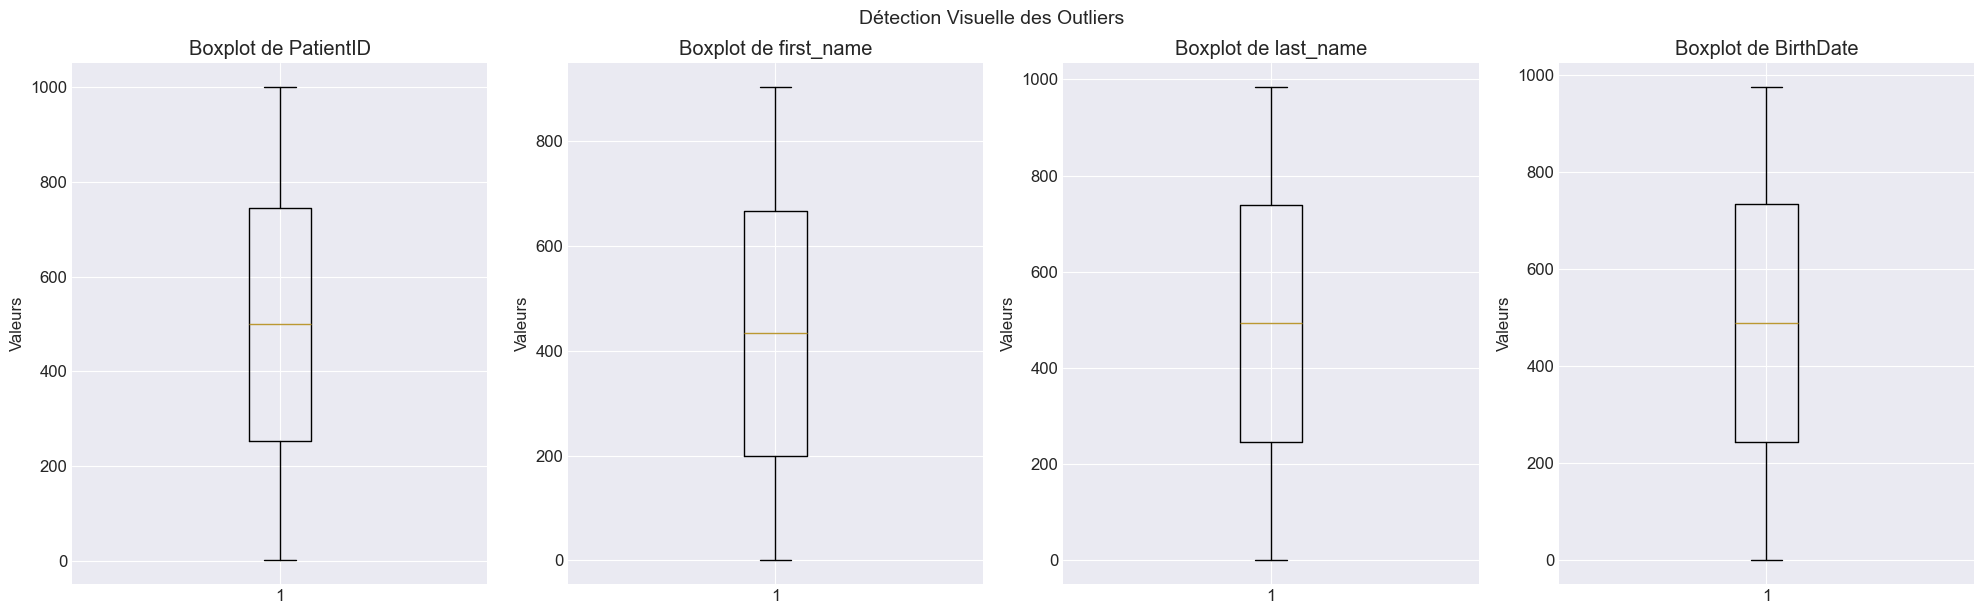


🔧 Application de remove_outliers()...
✅ Traitement des outliers terminé
   Lignes avant: 1000
   Lignes après: 1000
   Lignes supprimées: 0 (0.00%)


In [68]:
# Détection visuelle des outliers
def detect_outliers_visual(df, columns=None):
    """Détection visuelle des outliers"""
    if columns is None:
        columns = df.select_dtypes(include=[np.number]).columns
    
    if len(columns) == 0:
        print("   ℹ️  Aucune colonne numérique pour la détection d'outliers")
        return
    
    n_cols = min(4, len(columns))
    fig, axes = plt.subplots(1, n_cols, figsize=(5*n_cols, 6))
    
    if n_cols == 1:
        axes = [axes]
    
    for idx, col in enumerate(columns[:n_cols]):
        # Boxplot
        axes[idx].boxplot(df[col].dropna())
        axes[idx].set_title(f'Boxplot de {col}')
        axes[idx].set_ylabel('Valeurs')
        
        # Calcul des outliers avec méthode IQR
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
        
        print(f"   • {col}: {len(outliers)} outliers détectés "
              f"({len(outliers)/len(df)*100:.2f}%)")
    
    plt.tight_layout()
    plt.suptitle('Détection Visuelle des Outliers', y=1.02, fontsize=14)
    plt.show()

print("\n🔍 Détection visuelle des outliers...")
detect_outliers_visual(df_encoded)

# Application de remove_outliers
print("\n🔧 Application de remove_outliers()...")
df_no_outliers = remove_outliers(df_encoded, threshold=3)
removed_rows = len(df_encoded) - len(df_no_outliers)
print(f"✅ Traitement des outliers terminé")
print(f"   Lignes avant: {len(df_encoded)}")
print(f"   Lignes après: {len(df_no_outliers)}")
print(f"   Lignes supprimées: {removed_rows} ({removed_rows/len(df_encoded)*100:.2f}%)")


In [82]:

# Encoder les colonnes catégorielles
df_encoded, le_dict = encode_labels(df)

# Supprimer les outliers
df_no_outliers = remove_outliers(df_encoded, threshold=3)

# Afficher les premières lignes
print(df_no_outliers.head())

   BirthDate  gender  Obesity  Smoking  Genetic Risk  Cancer Prediction Level
0        786       4        2        1             3                        2
1        939       5        2        0             2                        2
2        580       4        4        1             0                        1
3        451       4        1        1             1                        1
4        730       2        0        0             0                        2


# 5. SPLIT TRAIN/TEST (SUPERVISÉ)



 SPLIT TRAIN/TEST (APPRENTISSAGE SUPERVISÉ)

 Division des données avec la cible: 'Cancer Prediction Level'
Split terminé
   X_train: (800, 5)
   X_test: (200, 5)
   y_train: (800,)
   y_test: (200,)

🔧 Normalisation séparée train/test...
 Normalisation train/test terminée
   X_train_scaled: (800, 5)
   X_test_scaled: (200, 5)

 Distribution des classes:
   Classe High: Train=259 (32.4%), Test=63 (31.5%)
   Classe Low: Train=267 (33.4%), Test=72 (36.0%)
   Classe Medium: Train=239 (29.9%), Test=62 (31.0%)


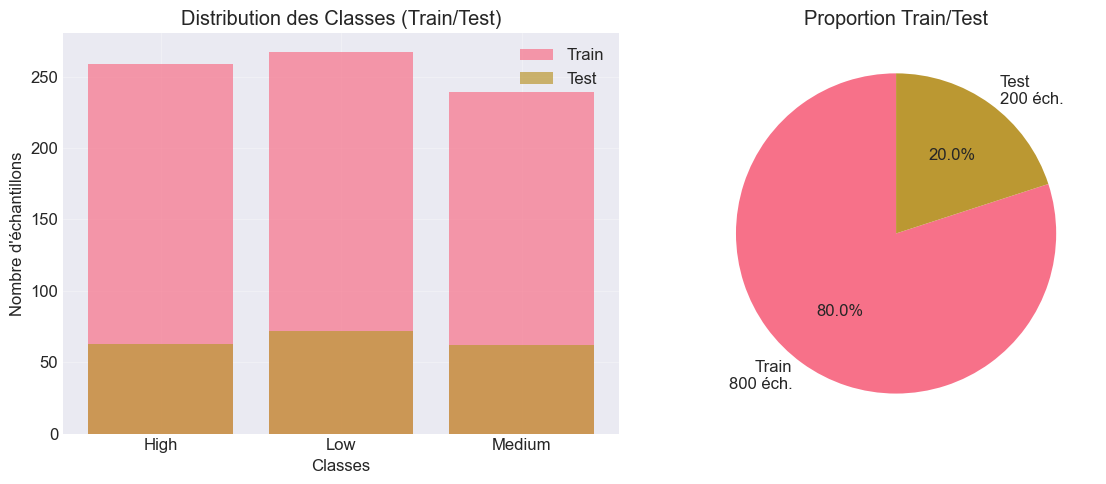

In [83]:
print("\n" + "=" * 70)
print(" SPLIT TRAIN/TEST (APPRENTISSAGE SUPERVISÉ)")
print("=" * 70)

if target_col in df_normalized.columns:
    print(f"\n Division des données avec la cible: '{target_col}'")
    
    # Utilisation de split_data
    X_train, X_test, y_train, y_test = split_data(
        df_normalized, 
        target_column=target_col,
        test_size=0.2,
        random_state=42
    )
    
    print(f"Split terminé")
    print(f"   X_train: {X_train.shape}")
    print(f"   X_test: {X_test.shape}")
    print(f"   y_train: {y_train.shape}")
    print(f"   y_test: {y_test.shape}")
    
    # Normalisation séparée pour train/test (alternative)
    print("\n🔧 Normalisation séparée train/test...")
    X_train_scaled, X_test_scaled, train_test_scaler = normalize_train_test(
        X_train, X_test
    )
    
    print(f" Normalisation train/test terminée")
    print(f"   X_train_scaled: {X_train_scaled.shape}")
    print(f"   X_test_scaled: {X_test_scaled.shape}")
    
    # Distribution des classes dans y
    print("\n Distribution des classes:")
    train_dist = pd.Series(y_train).value_counts().sort_index()
    test_dist = pd.Series(y_test).value_counts().sort_index()
    
    for label in train_dist.index:
        train_pct = (train_dist[label] / len(y_train)) * 100
        test_pct = (test_dist.get(label, 0) / len(y_test)) * 100
        print(f"   Classe {label}: Train={train_dist[label]} ({train_pct:.1f}%), "
              f"Test={test_dist.get(label, 0)} ({test_pct:.1f}%)")
    
    # Visualisation de la distribution
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    ax1.bar(train_dist.index.astype(str), train_dist.values, alpha=0.7, label='Train')
    ax1.bar(test_dist.index.astype(str), test_dist.values, alpha=0.7, label='Test')
    ax1.set_xlabel('Classes')
    ax1.set_ylabel('Nombre d\'échantillons')
    ax1.set_title('Distribution des Classes (Train/Test)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Taille relative
    sizes = [len(y_train), len(y_test)]
    labels = [f'Train\n{len(y_train)} éch.', f'Test\n{len(y_test)} éch.']
    ax2.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)
    ax2.set_title('Proportion Train/Test')
    
    plt.tight_layout()
    plt.show()
    
else:
    print(f"⚠️  Impossible de faire le split: colonne cible '{target_col}' non trouvée")


In [84]:

print("\n" + "=" * 70)
print("9. SAUVEGARDE DES DONNÉES PRÉTRAITÉES")
print("=" * 70)

# Créer les dossiers si nécessaire
os.makedirs('data/processed', exist_ok=True)

print("\n Sauvegarde des données...")

# 1. Données complètes normalisées
full_output_path = "data/processed/cancer_data_fully_processed.csv"
save_processed_data(df_normalized, full_output_path)
print(f" Données complètes: {full_output_path}")

# 2. Données d'entraînement et test (si disponibles)
if X_train_scaled is not None and y_train is not None:
    # Concaténer X et y pour la sauvegarde
    train_data = pd.concat([
        pd.DataFrame(X_train_scaled, columns=X_train.columns if hasattr(X_train, 'columns') else None),
        pd.DataFrame(y_train, columns=[target_col])
    ], axis=1)
    
    test_data = pd.concat([
        pd.DataFrame(X_test_scaled, columns=X_test.columns if hasattr(X_test, 'columns') else None),
        pd.DataFrame(y_test, columns=[target_col])
    ], axis=1)
    
    train_path = "data/processed/cancer_train_set.csv"
    test_path = "data/processed/cancer_test_set.csv"
    
    save_processed_data(train_data, train_path)
    save_processed_data(test_data, test_path)
    
    print(f" Train set: {train_path}")
    print(f" Test set: {test_path}")

# 3. Données du pipeline complet
if 'X_train_full' in locals() and X_train_full is not None:
    pipeline_train_path = "data/processed/cancer_pipeline_train.csv"
    pipeline_test_path = "data/processed/cancer_pipeline_test.csv"
    
    train_full_data = pd.concat([
        pd.DataFrame(X_train_full, columns=X_train_full.columns if hasattr(X_train_full, 'columns') else None),
        pd.DataFrame(y_train_full, columns=[target_col])
    ], axis=1)
    
    test_full_data = pd.concat([
        pd.DataFrame(X_test_full, columns=X_test_full.columns if hasattr(X_test_full, 'columns') else None),
        pd.DataFrame(y_test_full, columns=[target_col])
    ], axis=1)
    
    save_processed_data(train_full_data, pipeline_train_path)
    save_processed_data(test_full_data, pipeline_test_path)
    
    print(f"  Pipeline train set: {pipeline_train_path}")
    print(f"  Pipeline test set: {pipeline_test_path}")


9. SAUVEGARDE DES DONNÉES PRÉTRAITÉES

 Sauvegarde des données...
Données sauvegardées dans: data/processed/cancer_data_fully_processed.csv
 Données complètes: data/processed/cancer_data_fully_processed.csv
Données sauvegardées dans: data/processed/cancer_train_set.csv
Données sauvegardées dans: data/processed/cancer_test_set.csv
 Train set: data/processed/cancer_train_set.csv
 Test set: data/processed/cancer_test_set.csv
